# Microsoft Phi-4 14B Zero-Shot Evaluation

## 1. Model & Experiment Overview

Microsoft Phi-4 is evaluated on SUM Test (internal held-out), UMWP and MATE (external). The three conditions are the original frozen prompt with strict parsing, the modified prompt with strict parsing, and offline label extraction from the saved modified-prompt responses. The modified prompt removes the period after the label list. The offline condition reuses the same generations. SUM Test has no saved original-prompt run.

In [1]:
import hashlib
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks').is_dir() and (path / 'data/processed').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')

RESULTS_DIR = PROJECT_ROOT / 'results/llm/phi-4'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
PREDICTED_LABELS = [*LABELS, 'INVALID']
METRICS = {
    'Accuracy': 'accuracy',
    'Precision (UNANSWERABLE)': 'precision_unanswerable',
    'Recall (UNANSWERABLE)': 'recall_unanswerable',
    'F1 (UNANSWERABLE)': 'f1_unanswerable',
}
DATASETS = {'sum': (10944, 'pair_id'), 'umwp': (5200, 'id'), 'mate': (9586, 'id')}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def load_predictions(dataset, run_id):
    path = RESULTS_DIR / dataset / run_id / 'predictions.csv'
    count, identifier = DATASETS[dataset]
    predictions = pd.read_csv(path, keep_default_na=False, dtype={identifier: str, 'raw_response': str})
    required = {'row_index', identifier, 'text', 'true_label', 'raw_response', 'prediction',
                'valid', 'generated_token_ids', 'hit_token_limit'}
    if (not required.issubset(predictions) or predictions['row_index'].tolist() != list(range(count))
            or predictions[identifier].eq('').any()
            or not predictions['true_label'].isin(LABELS).all()
            or not predictions['prediction'].isin(PREDICTED_LABELS).all()
            or not predictions['valid'].eq(predictions['prediction'].ne('INVALID')).all()):
        raise ValueError(f'{path}: unexpected prediction schema, coverage or labels')
    return predictions


def score_predictions(predictions):
    matrix = pd.crosstab(predictions['true_label'], predictions['prediction']).reindex(
        index=LABELS, columns=PREDICTED_LABELS, fill_value=0,
    )
    tn, fp, invalid_negative = matrix.iloc[0]
    fn, tp, invalid_positive = matrix.iloc[1]
    missed = fn + invalid_positive
    count = len(predictions)
    invalid = int(invalid_negative + invalid_positive)

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    return {
        'num_examples': count, 'num_invalid': invalid, 'invalid_rate': invalid / count,
        'accuracy': (tn + tp) / count,
        'precision_unanswerable': ratio(tp, tp + fp),
        'recall_unanswerable': ratio(tp, tp + missed),
        'f1_unanswerable': ratio(2 * tp, 2 * tp + fp + missed),
    }, matrix


def load_strict(dataset, run_id):
    directory = RESULTS_DIR / dataset / run_id
    predictions = load_predictions(dataset, run_id)
    metrics = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    run = metrics['run']
    benchmark = PROJECT_ROOT / 'data/processed' / dataset / 'test.csv'
    digest = hashlib.sha256(benchmark.read_bytes().replace(b'\r\n', b'\n')).hexdigest()
    if run['dataset_sha256'] != digest:
        raise ValueError(f'{directory}: benchmark fingerprint differs')
    if (run['model_id'], run['dataset'], run['run_id'], metrics['positive_class']) != (
            'microsoft/phi-4', dataset, run_id, 'UNANSWERABLE'):
        raise ValueError(f'{directory}: unexpected model, run or positive class')
    parsed = predictions['raw_response'].str.strip()
    if not parsed.where(parsed.isin(LABELS), 'INVALID').eq(predictions['prediction']).all():
        raise ValueError(f'{directory}: recorded labels disagree with strict parsing')
    expected, matrix = score_predictions(predictions)
    saved_matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
    if (list(saved_matrix.index) != LABELS or list(saved_matrix.columns) != PREDICTED_LABELS
            or metrics['confusion_matrix_rows'] != LABELS
            or metrics['confusion_matrix_columns'] != PREDICTED_LABELS
            or saved_matrix.values.tolist() != matrix.values.tolist()
            or metrics['confusion_matrix'] != matrix.values.tolist()
            or run['row_count'] != len(predictions)):
        raise ValueError(f'{directory}: inconsistent confusion matrix or row count')
    for key, value in expected.items():
        if not math.isclose(metrics[key], value, rel_tol=0, abs_tol=1e-12):
            raise ValueError(f'{directory}: {key} disagrees with saved predictions')
    return metrics, matrix, predictions


def load_cleaned(dataset, strict_evaluation):
    strict_metrics, _, strict_predictions = strict_evaluation
    cleaned = load_predictions(dataset, 'run_02_cleaned')
    stable_columns = strict_predictions.columns.drop(['raw_response', 'prediction', 'valid'])
    if not cleaned[stable_columns].equals(strict_predictions[stable_columns]):
        raise ValueError(f'{dataset}: cleaned rows differ from their run_02 source')
    was_invalid = strict_predictions['prediction'].eq('INVALID')
    if not cleaned.loc[~was_invalid].equals(strict_predictions.loc[~was_invalid]):
        raise ValueError(f'{dataset}: cleaning changed a strict valid prediction')
    first_line = strict_predictions.loc[was_invalid, 'raw_response'].map(
        lambda raw: next((line.strip() for line in raw.splitlines() if line.strip()), ''))
    expected = first_line.where(first_line.isin(LABELS), 'INVALID')
    if not cleaned.loc[was_invalid, 'prediction'].eq(expected).all():
        raise ValueError(f'{dataset}: cleaned predictions disagree with the first non-empty line')
    # Legacy exports shorten the rescued field. MATE retains the full response.
    expected_raw = strict_predictions.loc[was_invalid, 'raw_response'] if dataset == 'mate' else expected
    if not cleaned.loc[was_invalid, 'raw_response'].eq(expected_raw).all():
        raise ValueError(f'{dataset}: cleaned response provenance differs')
    metrics, matrix = score_predictions(cleaned)
    if dataset == 'mate':
        directory = RESULTS_DIR / dataset / 'run_02_cleaned'
        saved = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
        saved_matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
        if (saved['run']['source_run_id'] != 'run_02'
                or saved['run']['dataset'] != dataset
                or saved['run']['run_id'] != 'run_02_cleaned'
                or saved['run']['dataset_sha256'] != strict_metrics['run']['dataset_sha256']
                or saved['run']['prompt'] != strict_metrics['run']['prompt']
                or not saved_matrix.equals(matrix)
                or saved['confusion_matrix'] != matrix.values.tolist()
                or any(not math.isclose(saved[key], value, abs_tol=1e-12, rel_tol=0)
                       for key, value in metrics.items())):
            raise ValueError(f'{directory}: cleaned artifacts disagree')
    return metrics, matrix, cleaned


sum_strict = load_strict('sum', 'run_02')
sum_cleaned = load_cleaned('sum', sum_strict)
umwp_original = load_strict('umwp', 'run_01')
umwp_strict = load_strict('umwp', 'run_02')
umwp_cleaned = load_cleaned('umwp', umwp_strict)
mate_original = load_strict('mate', 'run_01')
mate_strict = load_strict('mate', 'run_02')
mate_cleaned = load_cleaned('mate', mate_strict)
conditions = {
    'SUM Test': (None, sum_strict, sum_cleaned),
    'UMWP': (umwp_original, umwp_strict, umwp_cleaned),
    'MATE': (mate_original, mate_strict, mate_cleaned),
}
condition_names = ('Original prompt / strict', 'Modified prompt / strict', 'Modified prompt / offline cleaned')


In [2]:
settings = {
    'Model': 'model_id', 'Model type': 'model_type', 'Architecture': 'model_architectures',
    'Model API': 'model_api', 'Tokenizer API': 'tokenizer_api', 'Weights path': 'model_path',
    'Chat template': 'chat_template', 'Precision': 'dtype', 'Quantization': 'quantization',
    'GPU': 'gpu', 'Requested temperature': 'requested_temperature', 'Sampling enabled': 'do_sample',
    'Number of beams': 'num_beams', 'Maximum new tokens': 'max_new_tokens',
    'PyTorch': 'torch_version', 'Transformers': 'transformers_version', 'CUDA': 'cuda_version',
}
recorded_runs = {
    'SUM Test run_02': sum_strict[0]['run'],
    'UMWP run_01': umwp_original[0]['run'],
    'UMWP run_02': umwp_strict[0]['run'],
    'MATE run_01': mate_original[0]['run'],
    'MATE run_02': mate_strict[0]['run'],
}
run = recorded_runs['UMWP run_02']
for key in (*settings.values(), 'model_sha256',
            'transformers_distribution_url', 'invalid_output_policy'):
    if any(record[key] != run[key] for record in recorded_runs.values()):
        raise ValueError(f'Saved runs disagree on {key}')

original_prompt = recorded_runs['UMWP run_01']['prompt']
modified_prompt = run['prompt']
old_line, new_line = '\nANSWERABLE or UNANSWERABLE.\n', '\nANSWERABLE or UNANSWERABLE\n'
if (original_prompt.count(old_line) != 1 or original_prompt.replace(old_line, new_line, 1) != modified_prompt
        or recorded_runs['SUM Test run_02']['prompt'] != modified_prompt
        or recorded_runs['MATE run_01']['prompt'] != original_prompt
        or recorded_runs['MATE run_02']['prompt'] != modified_prompt
        or any(original[0]['run']['dataset_sha256'] != modified[0]['run']['dataset_sha256']
               for original, modified, _ in conditions.values() if original is not None)):
    raise ValueError('Saved prompt difference or dataset fingerprint is unexpected')

configuration = {label: 'None' if run[key] is None else str(run[key]) for label, key in settings.items()}
configuration['Decoding'] = 'Greedy' if not run['do_sample'] and run['num_beams'] == 1 else 'See settings'
vcs = (run['transformers_distribution_url'] or {}).get('vcs_info') or {}
configuration['Transformers source commit'] = vcs.get('commit_id', 'Unavailable')
display(pd.Series(configuration, name='Recorded setting').rename_axis('Setting').to_frame())
display(Markdown('**Exact original prompt (UMWP run_01)**\n\n```text\n' + original_prompt + '\n```'))
display(Markdown('**Only changed line in run_02**\n\n```diff\n-' + old_line.strip()
                 + '\n+' + new_line.strip() + '\n```'))

fingerprints = {
    'Model SHA-256': run['model_sha256'],
    **{f'{name} shared evaluator SHA-256': record['shared_evaluator_sha256']
       for name, record in recorded_runs.items()},
    **{f'{name} evaluator SHA-256': record['evaluator_sha256'] for name, record in recorded_runs.items()},
    **{f'{name} dataset SHA-256': record['dataset_sha256'] for name, record in recorded_runs.items()},
}
display(pd.Series(fingerprints, name='Recorded value').rename_axis('Fingerprint').to_frame())

,Recorded setting
Setting,
Model,microsoft/phi-4
Model type,phi3
Architecture,['Phi3ForCausalLM']
Model API,Phi3ForCausalLM
Tokenizer API,AutoTokenizer
Weights path,models/phi-4
Chat template,"Standard Phi-4 native ChatML template, one unc..."
Precision,bfloat16
Quantization,None


**Exact original prompt (UMWP run_01)**

```text
Determine whether the following math problem can be answered using the information provided.

Respond with exactly one label:
ANSWERABLE or UNANSWERABLE.

Do not solve the problem or provide an explanation.

Math problem:
{question}

Label:
```

**Only changed line in run_02**

```diff
-ANSWERABLE or UNANSWERABLE.
+ANSWERABLE or UNANSWERABLE
```

,Recorded value
Fingerprint,
Model SHA-256,ac83258b9494bc0aa13e21e33f1491ccf9eef30f13fdef...
SUM Test run_02 shared evaluator SHA-256,292e98e5db749939399e3fea2a6279fd99648160577d96...
UMWP run_01 shared evaluator SHA-256,292e98e5db749939399e3fea2a6279fd99648160577d96...
UMWP run_02 shared evaluator SHA-256,292e98e5db749939399e3fea2a6279fd99648160577d96...
MATE run_01 shared evaluator SHA-256,9a1a360dc9f154d3b71910a8370377b4138e99529728d9...
MATE run_02 shared evaluator SHA-256,9a1a360dc9f154d3b71910a8370377b4138e99529728d9...
SUM Test run_02 evaluator SHA-256,fb07da3fe702d01d5492403b15cbd8adf33a9acccd81d3...
UMWP run_01 evaluator SHA-256,2f4df5aba765fae4a18527c7421678d1cc3c34d5577800...
UMWP run_02 evaluator SHA-256,fb07da3fe702d01d5492403b15cbd8adf33a9acccd81d3...


## 2. Evaluation Metrics

**UNANSWERABLE is the positive class.**

- **Accuracy** is the fraction of all questions assigned the correct label.
- **Precision** is the fraction of predicted UNANSWERABLE questions that are truly unanswerable.
- **Recall** is the fraction of truly unanswerable questions detected by the model.
- **F1** is the harmonic mean of precision and recall for UNANSWERABLE.

Confusion matrices show actual labels in rows and predicted labels in columns. A false positive flags an answerable question as unanswerable. A false negative marks an unanswerable question as answerable, which can lead a downstream solver to attempt a question with insufficient information. The INVALID column tracks responses outside the two permitted labels. Each heatmap scales its colors to its own counts.

The strict parser evaluates output-format compliance as well as classification. After a label followed by an explanation fails exact matching, the additional post-processing analysis applies the exact-label parser to the first non-empty line of the original response. The cleaned CSVs contain the resulting labels and contain shortened response text in the earlier SUM and UMWP exports; MATE retains complete raw responses. Examples and formatting counts below use the preserved strict CSVs. Cleaned metrics are recomputed from the saved cleaned predictions using the same class definitions and denominators.

In [3]:
policy = sum_strict[0]['invalid_output_policy']
if any(run[0]['invalid_output_policy'] != policy for run in (umwp_original, umwp_strict, mate_original, mate_strict)):
    raise ValueError('Saved runs disagree on the invalid-output policy')
display(Markdown('**Recorded scoring policy.** ' + policy))


def show_evaluation(name, matrix):
    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    values = matrix.to_numpy()
    limit = values.max()
    ax.imshow(values, cmap='Blues', vmin=0, vmax=limit, aspect='auto')
    for (row, column), value in matrix.stack().items():
        ax.text(matrix.columns.get_loc(column), matrix.index.get_loc(row), f'{value:,}',
                ha='center', va='center', color='white' if value > limit / 2 else 'black')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted label', ylabel='Actual label', title=f'{name} confusion matrix')
    plt.show()
    plt.close(fig)


def show_class_errors(matrix):
    support = matrix.sum(axis=1)
    correct = pd.Series([matrix.loc[label, label] for label in LABELS], index=LABELS)
    wrong_label = pd.Series(
        [matrix.loc[LABELS[0], LABELS[1]], matrix.loc[LABELS[1], LABELS[0]]],
        index=LABELS,
    )
    errors = pd.DataFrame({
        'Actual examples': support,
        'Correct': correct,
        'Wrong label': wrong_label,
        'INVALID': matrix['INVALID'],
        'Wrong-label rate': (wrong_label / support).map('{:.2%}'.format),
        'Total error rate': ((wrong_label + matrix['INVALID']) / support).map('{:.2%}'.format),
    })
    display(errors.rename_axis('Actual class'))


def interpret_errors(matrix):
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    support = matrix.sum(axis=1)
    return (
        f'There were **{fp:,} false positives** ({fp / support["ANSWERABLE"]:.2%} '
        f'of answerable questions) and **{fn:,} false negatives** '
        f'({fn / support["UNANSWERABLE"]:.2%} of unanswerable questions). '
        f'Of the true UNANSWERABLE rows, {matrix.loc["UNANSWERABLE", "INVALID"]:,} '
        'additionally received INVALID responses and count as missed positives in recall.'
    )


def show_examples(predictions, identifier):
    false_positives = predictions['true_label'].eq('ANSWERABLE') & predictions['prediction'].eq('UNANSWERABLE')
    false_negatives = predictions['true_label'].eq('UNANSWERABLE') & predictions['prediction'].eq('ANSWERABLE')
    categories = {
        'False positive': false_positives,
        'False negative': false_negatives,
        'INVALID': predictions['prediction'].eq('INVALID'),
    }
    columns = ['row_index', identifier, 'text', 'true_label', 'prediction', 'raw_response', 'hit_token_limit']
    examples = pd.concat(
        [predictions.loc[mask, columns].head(1).assign(error=label) for label, mask in categories.items()],
        ignore_index=True,
    )
    # repr keeps empty strings, trailing whitespace and newlines visible.
    examples['raw_response'] = examples['raw_response'].map(repr)
    if examples.empty:
        display(Markdown('No recorded errors in these categories.'))
    else:
        display(examples.set_index('error').rename_axis('Error type').rename(columns={
            'row_index': 'Row index', 'pair_id': 'Pair ID', 'id': 'Question ID',
            'text': 'Question', 'true_label': 'Actual label', 'prediction': 'Prediction',
            'raw_response': 'Raw response (repr)', 'hit_token_limit': 'Hit token limit',
        }))
    missing = [label for label, mask in categories.items() if not mask.any()]
    if missing:
        display(Markdown('**Categories with no recorded examples:** ' + ', '.join(missing) + '.'))


def show_run(name, evaluation, *, cleaned=False):
    _, matrix, _ = evaluation
    show_evaluation(name, matrix)
    show_class_errors(matrix)
    if not cleaned:
        display(Markdown(interpret_errors(matrix)))


def show_cleaning_effect(strict, cleaned):
    before, after = strict[2], cleaned[2]
    recovered = before['prediction'].eq('INVALID')
    correct = after['prediction'].eq(after['true_label'])
    display(Markdown(
        f'Post-processing assigned a label to **{recovered.sum():,}** originally INVALID responses. '
        f'Of these, **{(recovered & correct).sum():,}** matched the reference and '
        f'**{(recovered & ~correct).sum():,}** were wrong-label predictions.'
    ))

**Recorded scoring policy.** After trimming surrounding whitespace, only exact uppercase labels are valid. INVALID is incorrect for accuracy and is a separate confusion-matrix column. INVALID on a true UNANSWERABLE row counts as a missed positive for recall and F1. Precision uses all predicted UNANSWERABLE rows. Zero denominators yield zero.

## 3. SUM Results & Analysis

SUM Test uses the complete saved modified-prompt `run_02`. The strict examples show the first recorded row per error category in evaluation order. The original frozen-prompt condition is **N/A**.

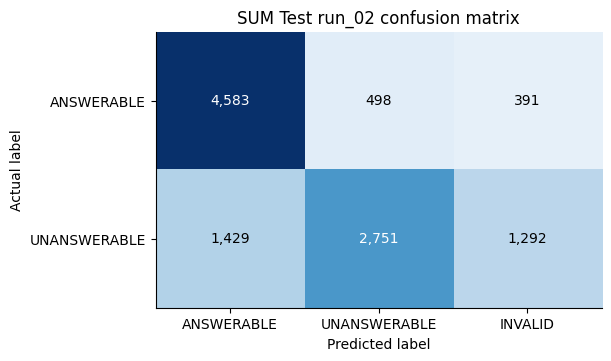

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,5472,4583,498,391,9.10%,16.25%
UNANSWERABLE,5472,2751,1429,1292,26.11%,49.73%


There were **498 false positives** (9.10% of answerable questions) and **1,429 false negatives** (26.11% of unanswerable questions). Of the true UNANSWERABLE rows, 1,292 additionally received INVALID responses and count as missed positives in recall.

,Row index,Pair ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,36,22573,The total number of workers in Workshop A and ...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,21,36348,Triangles ABC and AEF are such that B is the m...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,6,13331,"Simplify first, then evaluate: \(\left(\frac{2...",UNANSWERABLE,INVALID,"'UNANSWERABLE\n\nThe set \\(\\{3, 3, '",True


In [4]:
show_run('SUM Test run_02', sum_strict)
show_examples(sum_strict[2], 'pair_id')

### Post-processed predictions

The cleaned CSV uses the same `run_02` questions and generations. It records the additional researcher-initiated label extraction.

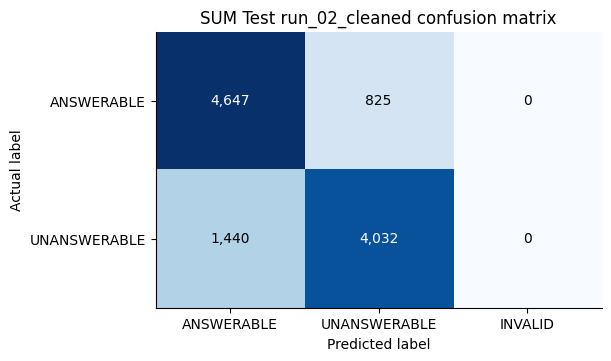

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,5472,4647,825,0,15.08%,15.08%
UNANSWERABLE,5472,4032,1440,0,26.32%,26.32%


Post-processing assigned a label to **1,683** originally INVALID responses. Of these, **1,345** matched the reference and **338** were wrong-label predictions.

In [5]:
show_run('SUM Test run_02_cleaned', sum_cleaned, cleaned=True)
show_cleaning_effect(sum_strict, sum_cleaned)

## 4. UMWP Results & Analysis

UMWP has saved results for all three conditions.

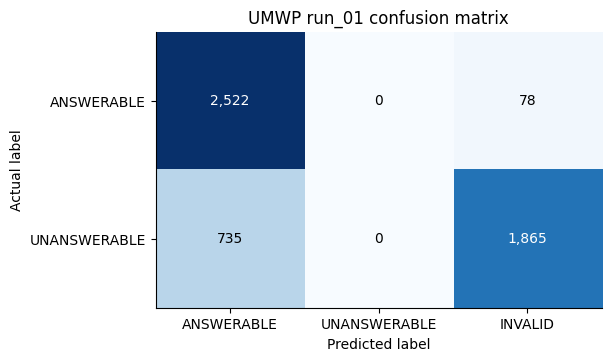

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2522,0,78,0.00%,3.00%
UNANSWERABLE,2600,0,735,1865,28.27%,100.00%


There were **0 false positives** (0.00% of answerable questions) and **735 false negatives** (28.27% of unanswerable questions). Of the true UNANSWERABLE rows, 1,865 additionally received INVALID responses and count as missed positives in recall.

**1,610 of 1,943 INVALID responses** were exactly `UNANSWERABLE.` after surrounding whitespace was trimmed. The period is part of the generated response and fails exact matching. The strict confusion matrix therefore records zero predictions of the exact `UNANSWERABLE` label in this run.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False negative,2602,2503,Randy has 58 blocks. He uses 27 blocks to buil...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,6,7,The Razorback shop makes $ 210 dollars off eac...,ANSWERABLE,INVALID,'UNANSWERABLE.',False


**Categories with no recorded examples:** False positive.

In [6]:
show_run('UMWP run_01', umwp_original)
strict_original = umwp_original[2]
period_only = strict_original['raw_response'].str.strip().eq('UNANSWERABLE.')
invalid = umwp_original[0]['num_invalid']
display(Markdown(
    f'**{period_only.sum():,} of {invalid:,} INVALID responses** were exactly `UNANSWERABLE.` '
    'after surrounding whitespace was trimmed. The period is part of the generated response '
    'and fails exact matching. The strict confusion matrix therefore records zero '
    'predictions of the exact `UNANSWERABLE` label in this run.'
))
show_examples(strict_original, 'id')

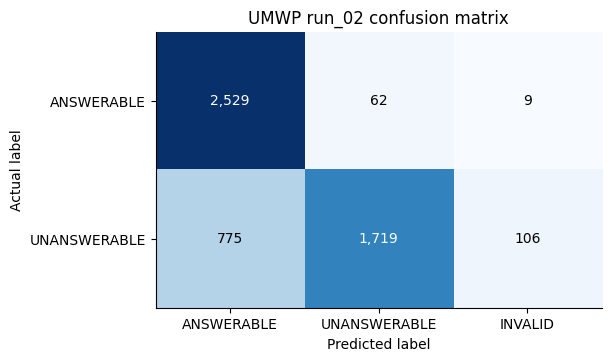

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2529,62,9,2.38%,2.73%
UNANSWERABLE,2600,1719,775,106,29.81%,33.88%


There were **62 false positives** (2.38% of answerable questions) and **775 false negatives** (29.81% of unanswerable questions). Of the true UNANSWERABLE rows, 106 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,6,7,The Razorback shop makes $ 210 dollars off eac...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,2602,2503,Randy has 58 blocks. He uses 27 blocks to buil...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,200,201,The school is planning a field trip. The schoo...,ANSWERABLE,INVALID,'UNANSWERABLE\n\nThe problem does not provide ...,True


In [7]:
show_run('UMWP run_02', umwp_strict)
show_examples(umwp_strict[2], 'id')

### Post-processed predictions

The cleaned UMWP CSV uses the modified-prompt generations. The original frozen-prompt run remains a separate strict comparison.

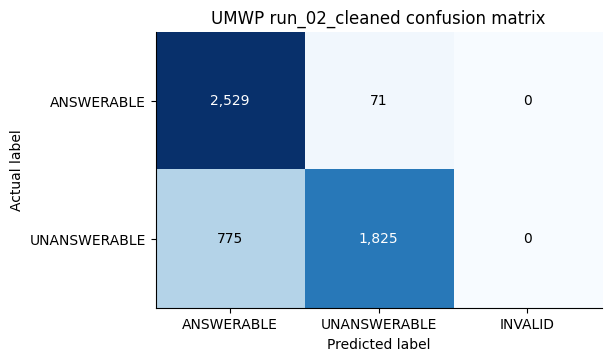

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2529,71,0,2.73%,2.73%
UNANSWERABLE,2600,1825,775,0,29.81%,29.81%


Post-processing assigned a label to **115** originally INVALID responses. Of these, **106** matched the reference and **9** were wrong-label predictions.

In [8]:
show_run('UMWP run_02_cleaned', umwp_cleaned, cleaned=True)
show_cleaning_effect(umwp_strict, umwp_cleaned)

## 5. MATE Results & Analysis

MATE has saved results for all three conditions. The cleaned copy preserves the full raw response.

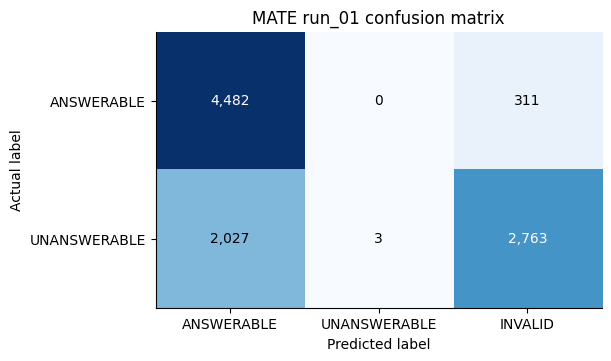

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,4793,4482,0,311,0.00%,6.49%
UNANSWERABLE,4793,3,2027,2763,42.29%,99.94%


There were **0 false positives** (0.00% of answerable questions) and **2,027 false negatives** (42.29% of unanswerable questions). Of the true UNANSWERABLE rows, 2,763 additionally received INVALID responses and count as missed positives in recall.

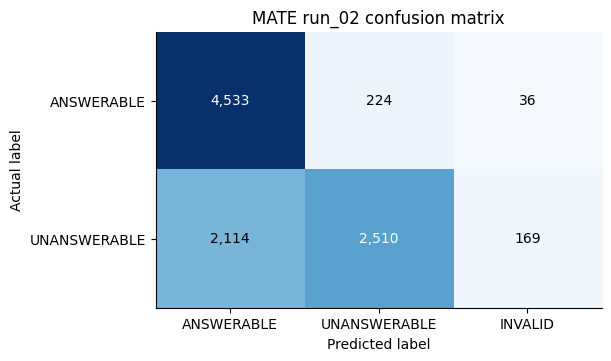

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,4793,4533,224,36,4.67%,5.42%
UNANSWERABLE,4793,2510,2114,169,44.11%,47.63%


There were **224 false positives** (4.67% of answerable questions) and **2,114 false negatives** (44.11% of unanswerable questions). Of the true UNANSWERABLE rows, 169 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,52,53,"There are numbers 0.8, 1/2, 0.9, and 1/3. Find...",ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,9,10,We want to create a three-digit number using t...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False
INVALID,216,217,There are 5 students in Yoongi's class. At thi...,ANSWERABLE,INVALID,'UNANSWERABLE\n\nThe problem does not specify ...,True


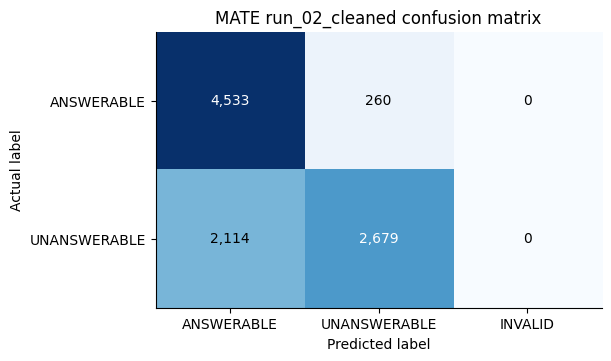

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,4793,4533,260,0,5.42%,5.42%
UNANSWERABLE,4793,2679,2114,0,44.11%,44.11%


Post-processing assigned a label to **205** originally INVALID responses. Of these, **169** matched the reference and **36** were wrong-label predictions.

In [9]:
show_run('MATE run_01', mate_original)
show_run('MATE run_02', mate_strict)
show_examples(mate_strict[2], 'id')
show_run('MATE run_02_cleaned', mate_cleaned, cleaned=True)
show_cleaning_effect(mate_strict, mate_cleaned)

## 6. Dataset Comparison & Interpretation

Examples Accuracy  \
Dataset  Condition                                             
SUM Test Original prompt / strict               N/A      N/A   
         Modified prompt / strict            10,944   67.01%   
         Modified prompt / offline cleaned   10,944   79.30%   
UMWP     Original prompt / strict             5,200   48.50%   
         Modified prompt / strict             5,200   81.69%   
         Modified prompt / offline cleaned    5,200   83.73%   
MATE     Original prompt / strict             9,586   46.79%   
         Modified prompt / strict             9,586   73.47%   
         Modified prompt / offline cleaned    9,586   75.23%   

                                           Precision (UNANSWERABLE)  \
Dataset  Condition                                                    
SUM Test Original prompt / strict                               N/A   
         Modified prompt / strict                            84.67%   
         Modified prompt / offline cleaned                   83.01%   
UMWP     Original prompt / strict                             0.00%   
         Modified prompt / strict                            96.52%   
         Modified prompt / offline cleaned                   96.26%   
MATE     Original prompt / strict                           100.00%   
         Modified prompt / strict                            91.81%   
         Modified prompt / offline cleaned                   91.15%   

                                           Recall (UNANSWERABLE)  \
Dataset  Condition                                                 
SUM Test Original prompt / strict                            N/A   
         Modified prompt / strict                         50.27%   
         Modified prompt / offline cleaned                73.68%   
UMWP     Original prompt / strict                          0.00%   
         Modified prompt / strict                         66.12%   
         Modified prompt / offline cleaned                70.19%   
MATE     Original prompt / strict                          0.06%   
         Modified prompt / strict                         52.37%   
         Modified prompt / offline cleaned                55.89%   

                                           F1 (UNANSWERABLE) INVALID count  \
Dataset  Condition                                                           
SUM Test Original prompt / strict                        N/A           N/A   
         Modified prompt / strict                     63.09%         1,683   
         Modified prompt / offline cleaned            78.07%             0   
UMWP     Original prompt / strict                      0.00%         1,943   
         Modified prompt / strict                     78.48%           115   
         Modified prompt / offline cleaned            81.18%             0   
MATE     Original prompt / strict                      0.13%         3,074   
         Modified prompt / strict                     66.69%           205   
         Modified prompt / offline cleaned            69.30%             0   

                                           INVALID rate  
Dataset  Condition                                       
SUM Test Original prompt / strict                   N/A  
         Modified prompt / strict                15.38%  
         Modified prompt / offline cleaned        0.00%  
UMWP     Original prompt / strict                37.37%  
         Modified prompt / strict                 2.21%  
         Modified prompt / offline cleaned        0.00%  
MATE     Original prompt / strict                32.07%  
         Modified prompt / strict                 2.14%  
         Modified prompt / offline cleaned        0.00%

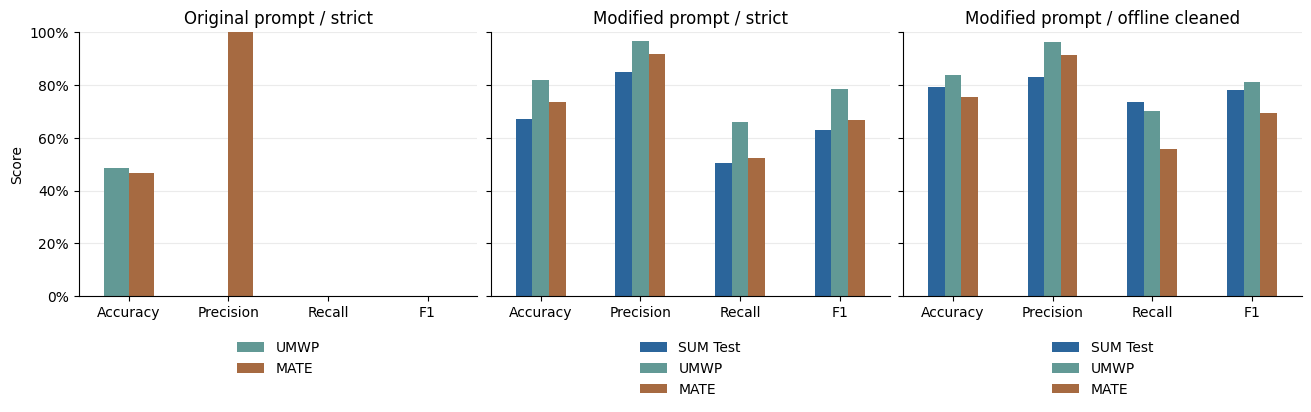

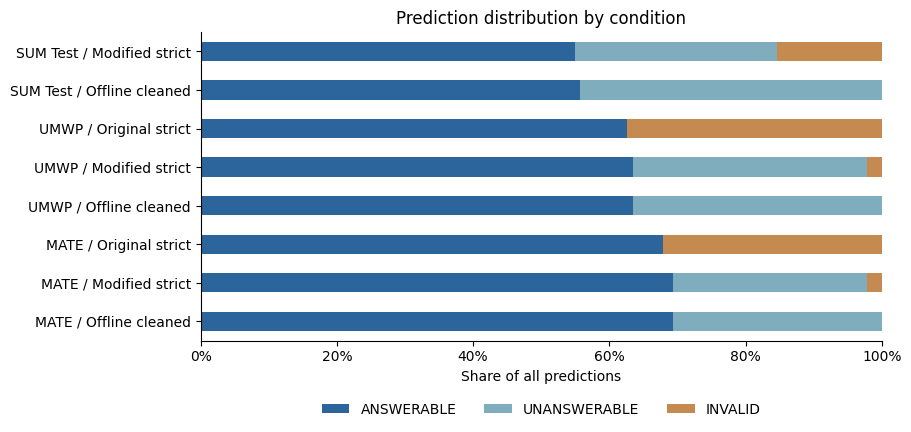

- **SUM Test**: Original-prompt comparison: N/A. Offline parsing moved F1 by +14.98 percentage points and recall by +23.41 percentage points; 0 INVALID outputs remained.
- **UMWP**: Changing the prompt moved strict F1 by +78.48 percentage points and INVALID from 1,943 to 115. Offline parsing moved F1 by +2.71 percentage points and recall by +4.08 percentage points; 0 INVALID outputs remained.
- **MATE**: Changing the prompt moved strict F1 by +66.57 percentage points and INVALID from 3,074 to 205. Offline parsing moved F1 by +2.60 percentage points and recall by +3.53 percentage points; 0 INVALID outputs remained.

Prompt comparisons use separate inference runs on the same rows. Parsing comparisons reuse modified-prompt generations. Format errors contribute to strict recall loss when the gold label is UNANSWERABLE. A recovered label can still be a wrong classification.

In [10]:
records = []
for dataset, evaluations in conditions.items():
    for condition, result in zip(condition_names, evaluations):
        m = result[0] if result else None
        records.append({
            'Dataset': dataset, 'Condition': condition,
            'Examples': f"{m['num_examples']:,}" if m else 'N/A',
            **{label: f'{m[key]:.2%}' if m else 'N/A' for label, key in METRICS.items()},
            'INVALID count': f"{m['num_invalid']:,}" if m else 'N/A',
            'INVALID rate': f"{m['invalid_rate']:.2%}" if m else 'N/A',
        })
display(pd.DataFrame(records).set_index(['Dataset', 'Condition']))

colors = {'SUM Test': '#2b659b', 'UMWP': '#629995', 'MATE': '#a66a41'}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout='constrained')
for ax, condition_index, title in zip(axes, range(3), condition_names):
    rates = pd.DataFrame({
        dataset: [result[0][key] for key in METRICS.values()]
        for dataset, evaluations in conditions.items()
        if (result := evaluations[condition_index]) is not None
    }, index=['Accuracy', 'Precision', 'Recall', 'F1'])
    rates.plot.bar(ax=ax, rot=0, color=[colors[dataset] for dataset in rates.columns])
    ax.set(ylim=(0, 1), title=title)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
    ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12))
axes[0].set_ylabel('Score')
plt.show()
plt.close(fig)

prediction_counts = pd.DataFrame({
    (dataset, short): evaluation[1].sum(axis=0)
    for dataset, evaluations in conditions.items()
    for short, evaluation in zip(('Original strict', 'Modified strict', 'Offline cleaned'), evaluations)
    if evaluation is not None
}).T
prediction_shares = prediction_counts.div(prediction_counts.sum(axis=1), axis=0)
prediction_shares.index = [f'{dataset} / {condition}' for dataset, condition in prediction_shares.index]
fig, ax = plt.subplots(figsize=(9, 4.2), layout='constrained')
prediction_shares.plot.barh(ax=ax, stacked=True, color=['#2b659b', '#80adbd', '#c58a50'])
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel='Share of all predictions', title='Prediction distribution by condition')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
plt.show()
plt.close(fig)

observations = []
for dataset, (original, modified, cleaned) in conditions.items():
    m, c = modified[0], cleaned[0]
    prompt_effect = 'Original-prompt comparison: N/A.'
    if original:
        o = original[0]
        prompt_gap = 100 * (m['f1_unanswerable'] - o['f1_unanswerable'])
        prompt_effect = (f"Changing the prompt moved strict F1 by {prompt_gap:+.2f} percentage points "
                         f"and INVALID from {o['num_invalid']:,} to {m['num_invalid']:,}.")
    parsing_gap = 100 * (c['f1_unanswerable'] - m['f1_unanswerable'])
    recall_gap = 100 * (c['recall_unanswerable'] - m['recall_unanswerable'])
    observations.append(
        f"- **{dataset}**: {prompt_effect} Offline parsing moved F1 by "
        f"{parsing_gap:+.2f} percentage points and recall by {recall_gap:+.2f} percentage points; "
        f"{c['num_invalid']:,} INVALID outputs remained."
    )
display(Markdown("\n".join(observations)))
display(Markdown(
    "Prompt comparisons use separate inference runs on the same rows. Parsing comparisons reuse "
    "modified-prompt generations. Format errors contribute to strict recall loss when the gold "
    "label is UNANSWERABLE. A recovered label can still be a wrong classification."
))